# Neighbour Market — Price Correlation Analysis

This notebook analyses the correlation between the DE/LU day-ahead price and its neighbouring countries' day-ahead prices, using the merged dataset `Merged_with_neighbors.xlsx`.

Goals:
- Quantify how strongly each neighbouring market is coupled with DE/LU
- Identify the top-coupled markets
- Examine seasonal variation in coupling
- Provide a basis for feature selection in the month-ahead price forecast (notebook 8)

Rows: 61144
Date range: 2025-01-01 00:00:00 → 2026-09-29 23:45:00
Columns: ['Germany/Luxembourg [€/MWh]', '∅ DE/LU neighbours [€/MWh]', 'Belgium [€/MWh]', 'Denmark 1 [€/MWh]', 'Denmark 2 [€/MWh]', 'France [€/MWh]', 'Netherlands [€/MWh]', 'Norway 2 [€/MWh]', 'Austria [€/MWh]', 'Poland [€/MWh]', 'Sweden 4 [€/MWh]', 'Switzerland [€/MWh]', 'Czech Republic [€/MWh]', 'Northern Italy [€/MWh]', 'Slovenia [€/MWh]', 'Hungary [€/MWh]', 'temperature_2m', 'sunshine_duration', 'wind_speed_80m', 'wind_direction_80m', 'is_day', 'precipitation', 'shortwave_radiation']

Missing values per column:
Germany/Luxembourg [€/MWh]    0
∅ DE/LU neighbours [€/MWh]    0
Belgium [€/MWh]               0
Denmark 1 [€/MWh]             0
Denmark 2 [€/MWh]             0
France [€/MWh]                0
Netherlands [€/MWh]           0
Norway 2 [€/MWh]              0
Austria [€/MWh]               0
Poland [€/MWh]                0
Sweden 4 [€/MWh]              0
Switzerland [€/MWh]           0
Czech Republic [€/MWh]        

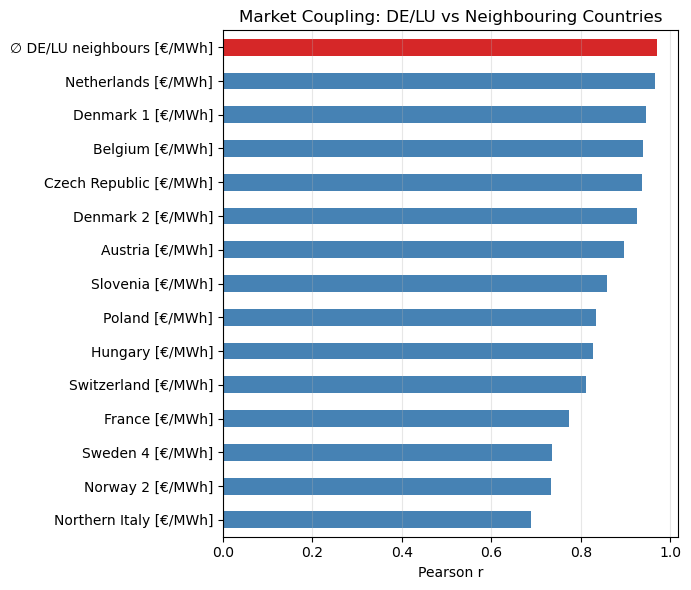

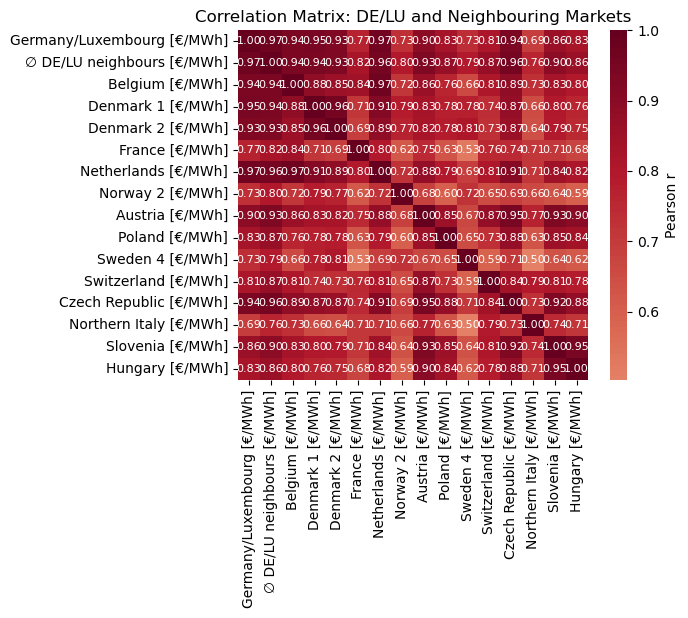


Seasonal correlation with DE/LU (top-5 neighbours):
                            Winter  Spring  Summer  Autumn
∅ DE/LU neighbours [€/MWh]   0.934   0.977   0.980   0.965
Netherlands [€/MWh]          0.939   0.968   0.985   0.948
Denmark 1 [€/MWh]            0.907   0.915   0.976   0.964
Belgium [€/MWh]              0.910   0.962   0.958   0.896
Czech Republic [€/MWh]       0.838   0.961   0.950   0.934


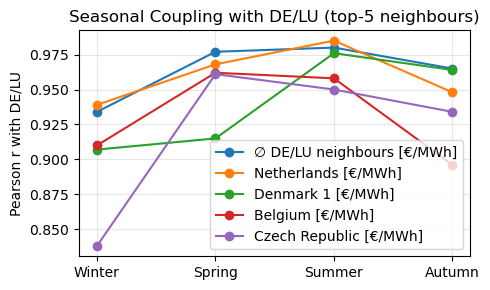

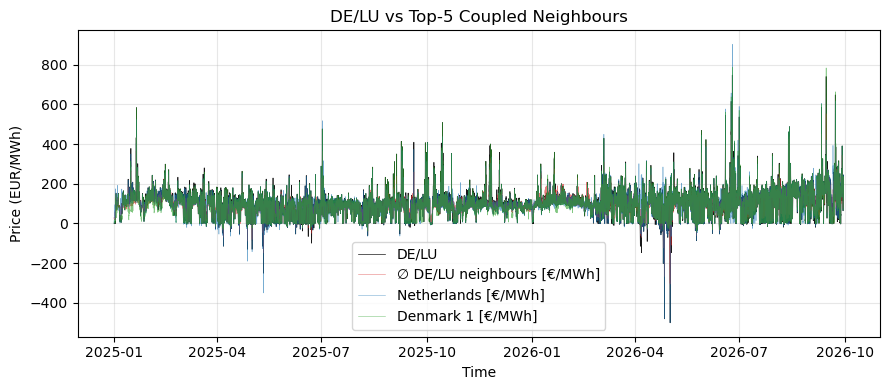


  Top-5 Correlated Markets with DE/LU
 Rank                     Market  Correlation with DE/LU
    1 ∅ DE/LU neighbours [€/MWh]                   0.969
    2        Netherlands [€/MWh]                   0.966
    3          Denmark 1 [€/MWh]                   0.945
    4            Belgium [€/MWh]                   0.938
    5     Czech Republic [€/MWh]                   0.936

Strongest coupling : ∅ DE/LU neighbours [€/MWh]  (r = 0.969)
Top-5 neighbours   : ['∅ DE/LU neighbours [€/MWh]', 'Netherlands [€/MWh]', 'Denmark 1 [€/MWh]', 'Belgium [€/MWh]', 'Czech Republic [€/MWh]']
Average-coupling r : 0.969


In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# =========================================================
# 1. Load data
# =========================================================
df = pd.read_excel(r"C:\Users\Dell\Desktop\Project\Merged_with_neighbors.xlsx")
df["Start date"] = pd.to_datetime(df["Start date"])
df = df.set_index("Start date").sort_index()

print("Rows:", len(df))
print("Date range:", df.index.min(), "→", df.index.max())
print("Columns:", df.columns.tolist())

# =========================================================
# 2. Define columns
# =========================================================
de_col = "Germany/Luxembourg [€/MWh]"

neighbour_cols = [
    "∅ DE/LU neighbours [€/MWh]",
    "Belgium [€/MWh]",
    "Denmark 1 [€/MWh]",
    "Denmark 2 [€/MWh]",
    "France [€/MWh]",
    "Netherlands [€/MWh]",
    "Norway 2 [€/MWh]",
    "Austria [€/MWh]",
    "Poland [€/MWh]",
    "Sweden 4 [€/MWh]",
    "Switzerland [€/MWh]",
    "Czech Republic [€/MWh]",
    "Northern Italy [€/MWh]",
    "Slovenia [€/MWh]",
    "Hungary [€/MWh]",
]

print("\nMissing values per column:")
print(df[[de_col] + neighbour_cols].isna().sum().to_string())

# =========================================================
# 3. Overall correlation with DE/LU
# =========================================================
corr_with_de = (
    df[[de_col] + neighbour_cols]
    .corr()[de_col]
    .drop(de_col)
    .sort_values(ascending=False)
)

print("\n" + "=" * 55)
print("  Correlation with DE/LU price")
print("=" * 55)
print(corr_with_de.round(3).to_string())
print("=" * 55)

# =========================================================
# 4. Bar chart — correlation ranking
# =========================================================
fig, ax = plt.subplots(figsize=(7, 6))
colors = ["steelblue"] * len(corr_with_de)
colors[0] = "tab:red"          # highlight strongest
corr_with_de.plot(kind="barh", ax=ax, color=colors)
ax.invert_yaxis()
ax.set_xlabel("Pearson r")
ax.set_title("Market Coupling: DE/LU vs Neighbouring Countries")
ax.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

# =========================================================
# 5. Correlation heatmap (all pairs)
# =========================================================
corr_all = df[[de_col] + neighbour_cols].corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr_all, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, square=True, cbar_kws={"label": "Pearson r"},
            annot_kws={"size": 8})
ax.set_title("Correlation Matrix: DE/LU and Neighbouring Markets")
plt.tight_layout()
plt.show()

# =========================================================
# 6. Seasonal coupling (top-5 neighbours)
# =========================================================
top5 = corr_with_de.head(5).index.tolist()

df["month"] = df.index.month

def season(m):
    if m in [12, 1, 2]:   return "Winter"
    if m in [3, 4, 5]:    return "Spring"
    if m in [6, 7, 8]:    return "Summer"
    if m in [9, 10, 11]:  return "Autumn"

df["season"] = df["month"].apply(season)

seasonal = {}
for s in ["Winter", "Spring", "Summer", "Autumn"]:
    sub = df[df["season"] == s][[de_col] + top5]
    seasonal[s] = sub.corr()[de_col].drop(de_col)

seasonal_df = pd.DataFrame(seasonal).round(3)
print("\nSeasonal correlation with DE/LU (top-5 neighbours):")
print(seasonal_df.to_string())

# Seasonal plot
fig, ax = plt.subplots(figsize=(5, 3))
seasonal_df.T.plot(ax=ax, marker="o")
ax.set_ylabel("Pearson r with DE/LU")
ax.set_title("Seasonal Coupling with DE/LU (top-5 neighbours)")
ax.set_xticks(range(len(seasonal_df.columns)))
ax.set_xticklabels(seasonal_df.columns)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# =========================================================
# 7. Time-series overlay — DE/LU vs top-5
# =========================================================
top5 = corr_with_de.head(5).index.tolist()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(df.index, df[de_col], color="black", lw=0.5, label="DE/LU", alpha=0.9)
for col, c in zip(top5, ["tab:red", "tab:blue", "tab:green"]):
    ax.plot(df.index, df[col], color=c, lw=0.4, label=col, alpha=0.6)
ax.set_xlabel("Time")
ax.set_ylabel("Price (EUR/MWh)")
ax.set_title("DE/LU vs Top-5 Coupled Neighbours")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# =========================================================
# 8. Summary table
# =========================================================
summary_top5 = pd.DataFrame({
    "Rank": range(1, 6),
    "Market": corr_with_de.head(5).index,
    "Correlation with DE/LU": corr_with_de.head(5).values.round(3),
})
print("\n" + "=" * 55)
print("  Top-5 Correlated Markets with DE/LU")
print("=" * 55)
print(summary_top5.to_string(index=False))
print("=" * 55)

# =========================================================
# 9. Key takeaways
# =========================================================
top1 = corr_with_de.index[0]
top5_list = corr_with_de.head(5).index.tolist()
avg_col = "∅ DE/LU neighbours [€/MWh]"

print(f"\nStrongest coupling : {top1}  (r = {corr_with_de.iloc[0]:.3f})")
print(f"Top-5 neighbours   : {top5_list}")
print(f"Average-coupling r : {corr_with_de[avg_col]:.3f}")

## Neighbour Market Coupling — Summary

### 1. Correlation Ranking with DE/LU

| Rank | Market | r |
|---|---|---|
| 1 | ∅ DE/LU neighbours | **0.969** |
| 2 | Netherlands | 0.966 |
| 3 | Denmark 1 | 0.945 |
| 4 | Belgium | 0.938 |
| 5 | Czech Republic | 0.936 |

The six closest markets all show **r > 0.9**, confirming tight integration of the Central-Western European day-ahead markets. Structurally different markets (France r = 0.77, Nordics r ≈ 0.73, Northern Italy r = 0.69) show weaker coupling.

### 2. Seasonal Variation

Coupling is **strongest in spring/summer (r ≈ 0.96–0.98)** and **weakest in winter (r ≈ 0.91–0.94)**.

**Why summer is highest:** Solar generation is synchronised across Central Europe — PV output peaks simultaneously in all markets, pushing prices into a common intraday shape.

**Why winter/autumn is lower:** Wind generation is geographically localised and intermittent — when Germany has strong wind, neighbours often do not, causing price divergence. Grid congestion on German north-south corridors also weakens coupling in winter. The Czech market is notably decoupled in winter (r = 0.838) due to its distinct coal/nuclear mix.

### 3. Takeaway

Since the average of all neighbours (`∅ DE/LU neighbours`) has the **highest correlation with DE/LU (r = 0.969)**, it serves as the most informative single feature for predicting DE/LU prices. Individual country prices are largely redundant due to multicollinearity.

This supports the feature selection in notebook 6 (where `neighbor` achieved 94.6% feature importance) and the forecast design in notebook 8: **use `∅ DE/LU neighbours` as the neighbour-price feature.**